# Quantum Krylov vs. statistical phase estimation on simulated silicon spin qubits

H₂ ground-state energy from one shared quantum primitive, the Hadamard test of g(kτ) = ⟨HF|e^{−iHkτ}|HF⟩, post-processed two ways: real-time Krylov subspace diagonalization and statistical phase estimation. The circuits are executed at pulse level under spin-qubit noise with **SpinPulse** (Quobly, arXiv:2601.10435). Everything is **simulation**.

Live cells use few noise realizations (about 1 min in total); the figures at the end come from `scripts/run_all.py`.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np

## 1. Hamiltonian: OpenFermion → Jordan–Wigner → Z₂ tapering → 1 qubit

In [2]:
from krylov_qpe.hamiltonian import h2_problem
prob = h2_problem()
print('4-qubit JW terms:', prob.jw_op.size)
print('tapered H =', prob.op)
print(f'E_FCI = {prob.fci_energy:.6f} Ha, E_HF = {prob.hf_energy:.6f} Ha, p0 = |<E0|HF>|^2 = {prob.ground_state_overlap:.4f}')

4-qubit JW terms: 15
tapered H = SparsePauliOp(['I', 'Z', 'X'],
              coeffs=[-0.32112415+0.j, -0.79587485+0.j,  0.1809312 +0.j])
E_FCI = -1.137306 Ha, E_HF = -1.116999 Ha, p0 = |<E0|HF>|^2 = 0.9876


## 2. Shared primitive: controlled evolution + Hadamard test
One controlled step is one RZZ plus single-qubit rotations; U^k is applied as k steps (no fast-forwarding).

In [3]:
from krylov_qpe.evolution import default_tau, controlled_step_circuit, statevector_g
from krylov_qpe.hamiltonian import exact_g
tau = default_tau(prob)
print(f'tau = {tau:.4f} 1/Ha')
print('max |g_circuit - g_exact| over k<=20:', abs(statevector_g(prob, tau, 20) - exact_g(prob, tau*np.arange(21))).max())
controlled_step_circuit(prob, tau).draw()

tau = 1.0721 1/Ha
max |g_circuit - g_exact| over k<=20: 4.280122151412432e-15


q_0: ─────────────────────────────■─────────────────────────
     ┌─────────────┐┌───────────┐ │ZZ(-0.875) ┌────────────┐
q_1: ┤ Ry(-2.9181) ├┤ Rz(0.875) ├─■───────────┤ Ry(2.9181) ├
     └─────────────┘└───────────┘             └────────────┘

## 3. Noiseless estimators

In [4]:
from krylov_qpe.krylov import krylov_energy
from krylov_qpe.phase_est import spe_energy, spe_crossing_energy
g = exact_g(prob, tau*np.arange(2100)); E0 = prob.fci_energy
for D in (1, 2, 3):
    print(f'Krylov D={D}: error {1e3*(krylov_energy(g, D, tau, prob.c0).energy - E0):+.2e} mHa')
for d in (63, 255, 2047):
    print(f'SPE d={d:4d}: bisection {1e3*(spe_energy(g, d, tau, prob.c0).energy-E0):+7.2f} mHa, '
          f'crossing {1e3*(spe_crossing_energy(g, d, tau, prob.c0).energy-E0):+7.2f} mHa')

Krylov D=1: error +1.16e+01 mHa
Krylov D=2: error +2.22e-13 mHa
Krylov D=3: error +0.00e+00 mHa
SPE d=  63: bisection  -39.69 mHa, crossing  -34.31 mHa
SPE d= 255: bisection   -9.21 mHa, crossing   -8.48 mHa


SPE d=2047: bisection   -1.50 mHa, crossing   -1.06 mHa


## 4. SpinPulse: compile and run with noise
Hardware model from SpinPulse's *ParametrizingfromQPUSpecs* example (1 µs X and ZZ gates). Noise rates Γ = 1/T* in 1/µs. Importing `krylov_qpe.noisy` applies a correction for a qubit-ordering issue in SpinPulse 1.1.3's two-qubit layers (see README, Implementation notes).

SpinPulse qubit-ordering correction applied: True
step: {'ry': 5, 'rz': 4, 'rzz': 2} 3757 ns | prep: {'ry': 1, 'rz': 1} 609 ns


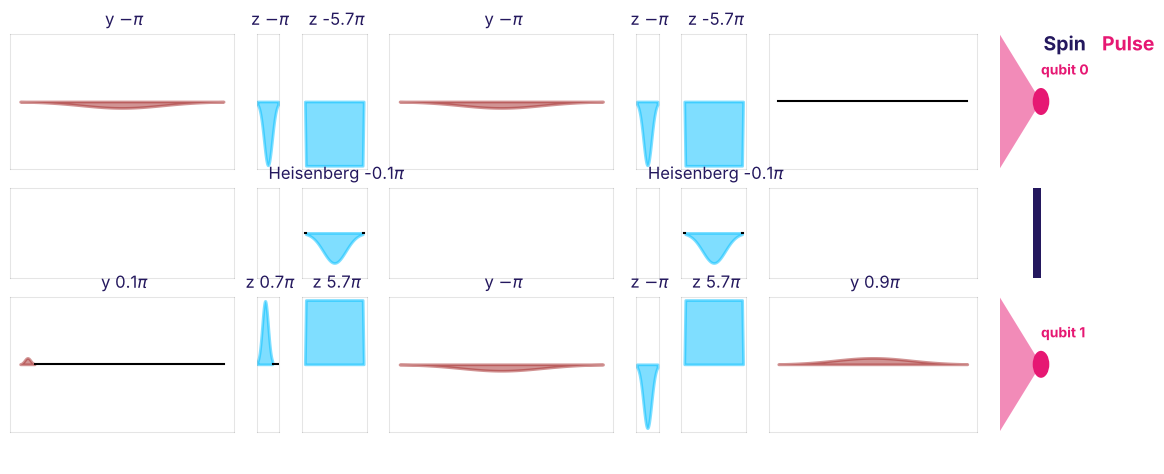

In [5]:
from krylov_qpe.noisy import compile_hadamard_test, noisy_g_samples, DEFAULT_OPERATING_POINT, NoiseConfig, trajectory_g
from krylov_qpe import spinpulse_patch
print('SpinPulse qubit-ordering correction applied:', spinpulse_patch.is_applied())
comp = compile_hadamard_test(prob, tau)
print('step:', dict(comp.step.isa.count_ops()), f'{comp.step.duration_ns} ns | prep:', dict(comp.prep.isa.count_ops()), f'{comp.prep.duration_ns} ns')
comp.step.pulse.plot(hardware_specs=comp.hs)

A small live run. Krylov at D = 2 is ill-conditioned (1 − |g(τ)| ≈ 0.02), so a few hundred realizations still leave errors of several mHa; the full results use N = 5000.

In [6]:
from krylov_qpe.sensitivity import jackknife
from krylov_qpe.resources import krylov_estimator
N = 200
G = noisy_g_samples(comp, 2, [NoiseConfig(), DEFAULT_OPERATING_POINT], N)
f = krylov_estimator(2, tau, prob.c0)
for name, gs in zip(['noiseless pulses', 'operating point'], G):
    e, se = jackknife(gs, f)
    print(f'Krylov D=2, {name:17s}: E - E_FCI = {1e3*(e-E0):+7.2f} ± {1e3*se:.2f} mHa  (N={N})')

Krylov D=2, noiseless pulses : E - E_FCI =   +0.10 ± 0.00 mHa  (N=200)
Krylov D=2, operating point  : E - E_FCI =   -8.61 ± 5.91 mHa  (N=200)


## 5. Full results (`python scripts/run_all.py`)

krylov_high_statistics: E - E_FCI = -6.3 ± 1.7 mHa, noise shift -6.4 mHa
   quasistatic  relative sensitivity +0.17 ± 0.05
   white        relative sensitivity +0.09 ± 0.06
   pink         relative sensitivity +0.81 ± 0.27
   exchange     relative sensitivity +0.15 ± 0.06
spe: E - E_FCI = -55.1 ± 4.2 mHa, noise shift -20.7 mHa
   quasistatic  relative sensitivity +0.56 ± 0.11
   white        relative sensitivity +0.28 ± 0.06
   pink         relative sensitivity +0.83 ± 0.17
   exchange     relative sensitivity +0.42 ± 0.11


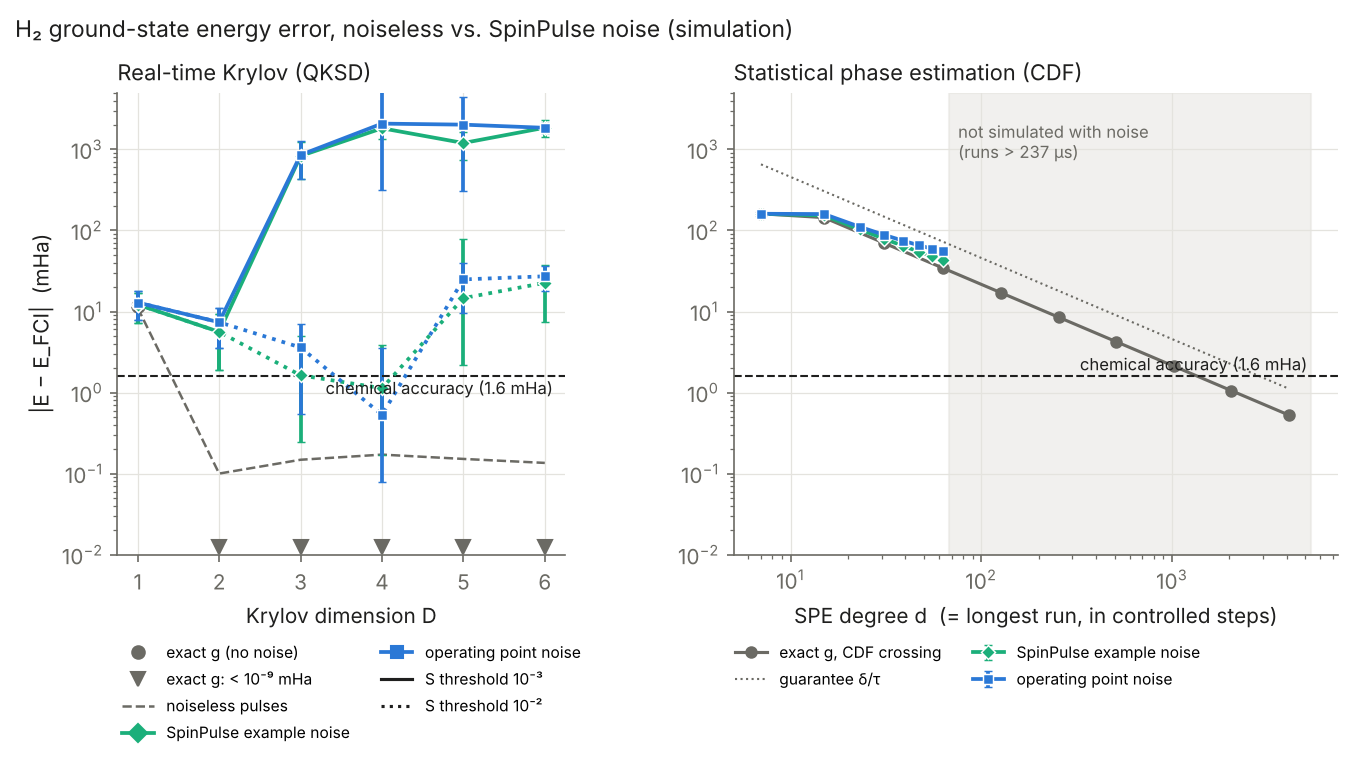

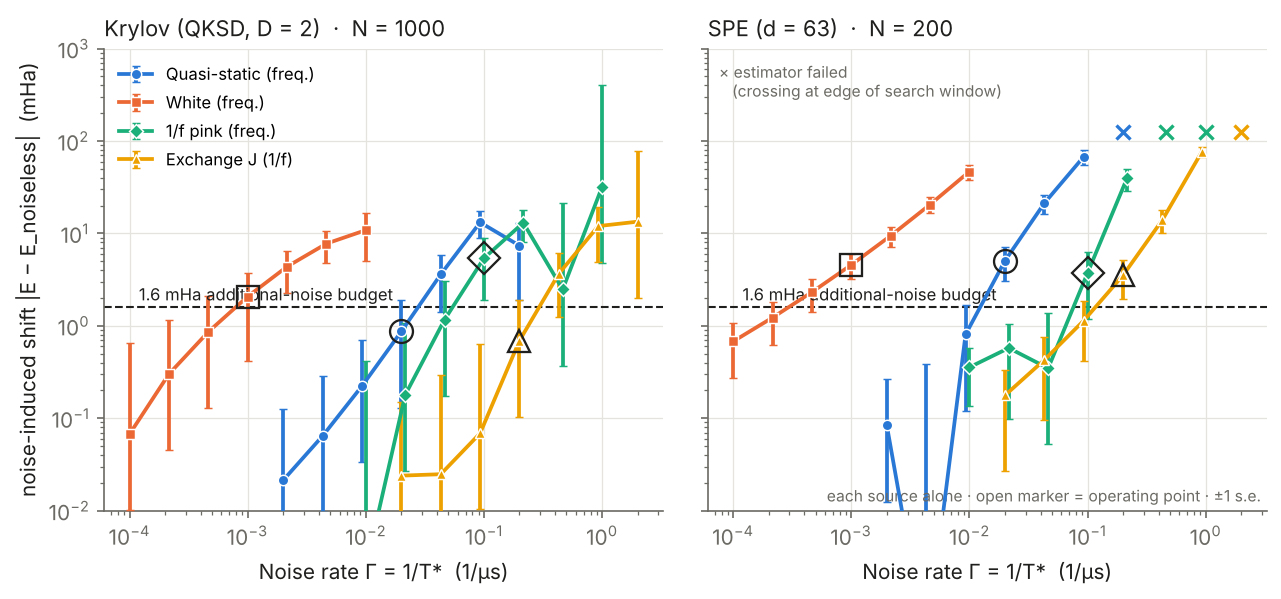

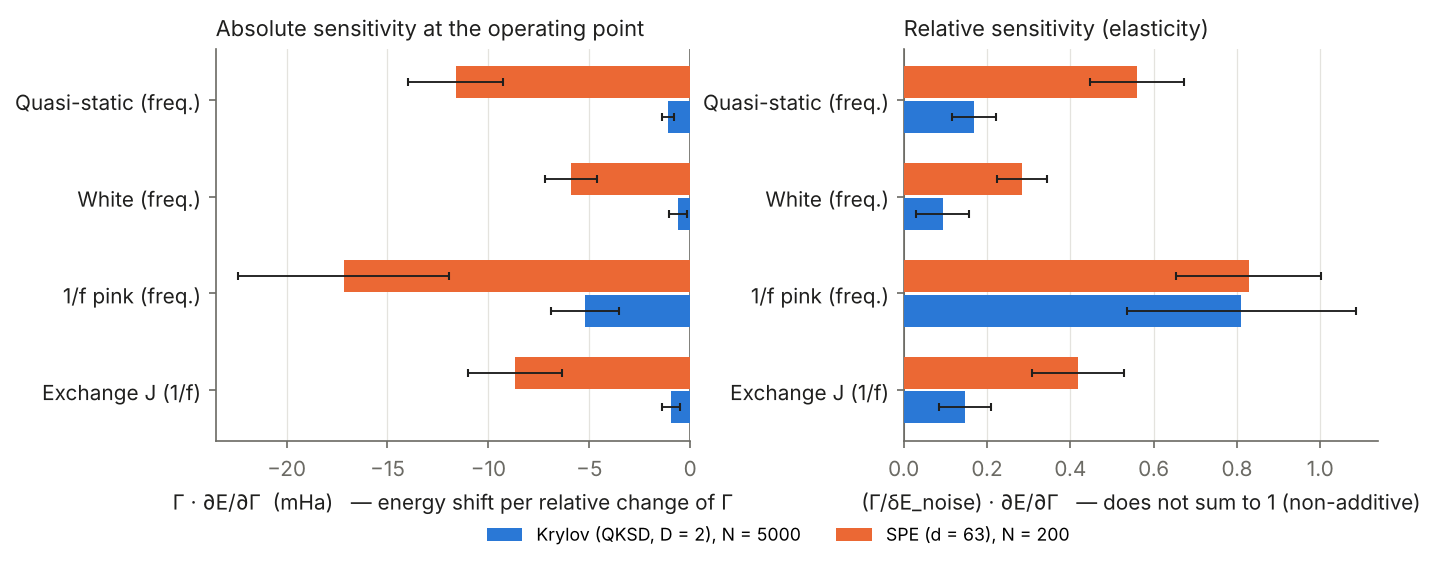

In [7]:
from IPython.display import Image, display
res = json.loads((ROOT / 'results' / 'results.json').read_text())
for alg in ('krylov_high_statistics', 'spe'):
    s = res['noisy'][alg]['sensitivity']
    print(f"{alg}: E - E_FCI = {1e3*(s['energy']-E0):+.1f} ± {1e3*s['energy_se']:.1f} mHa, noise shift {1e3*s['noise_shift']:+.1f} mHa")
    for k in s['relative']:
        print(f"   {k:12s} relative sensitivity {s['relative'][k]:+.2f} ± {s['relative_se'][k]:.2f}")
for f in ['fig1_convergence.png', 'fig2_sweeps.png', 'fig3_sensitivity.png']:
    display(Image(filename=str(ROOT / 'figures' / f)))